<a href="https://colab.research.google.com/github/jsmak/dl-framework/blob/main/07_optimization/07_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **딥러닝 최적화: 옵티마이저, 규제, 기울기 소실**

신경망 학습의 목적은 손실을 최소화하는 파라미터를 찾는 것, 즉 **최적화** 문제입니다.  
하지만 파라미터 공간은 매우 넓고 복잡해서 최적의 값을 찾기가 쉽지 않습니다.  

6강의 캘리포니아 집값 데이터로 세 가지를 실험합니다.

1. **옵티마이저 비교**: SGD, 모멘텀, AdaGrad, Adam이 손실을 줄이는 속도와 경로
2. **과적합과 규제**: L2 정규화와 드롭아웃이 과적합을 얼마나 줄이는지
3. **기울기 소실**: 100층짜리 깊은 신경망에서 배치 정규화, 층 정규화, 잔차 연결의 효과

> 실험을 빠르게 하기 위해 이번 노트북은 미니배치 대신 **훈련 데이터 전체를 한 번에** 학습합니다(배치 경사하강법).

## **1. 데이터 준비**

6강과 같은 캘리포니아 주택 가격 데이터를 불러와 훈련·테스트 세트로 나누고, 표준화한 뒤 텐서로 변환합니다.

방화벽 등으로 데이터를 내려받을 수 없는 환경에서는 6강 폴더의 `cal_housing_py3.pkz`를 노트북과 같은 폴더에 복사하고, 데이터 로드 줄을 주석에 있는 줄로 바꿔 실행하세요.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 데이터 로드
X, y = fetch_california_housing(return_X_y=True)  # 방화벽 등으로 받을 수 없으면 이 줄을 주석 처리하고 아래 줄을 실행하세요.
# X, y = fetch_california_housing(data_home='./', download_if_missing=False, return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 표준화 및 텐서 변환
scaler = StandardScaler()
X_train_t = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(scaler.transform(X_test), dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

criterion = nn.MSELoss()
print("학습 데이터:", X_train_t.shape, " 테스트 데이터:", X_test_t.shape)

학습 데이터: torch.Size([16512, 8])  테스트 데이터: torch.Size([4128, 8])


## **2. 옵티마이저 비교**

같은 모델(은닉층 2개)을 옵티마이저만 바꿔 50 에폭 학습하고, 훈련 손실이 줄어드는 속도를 비교합니다. 학습률은 모두 0.01입니다.

| 옵티마이저 | 특징 |
|:---|:---|
| SGD | 모든 파라미터에 같은 학습률 |
| Momentum | 과거 이동 방향을 기억해 관성을 줌 |
| AdaGrad | 파라미터별로 학습률을 조절 |
| Adam | 모멘텀 + 파라미터별 학습률 |

SGD       50 에폭 후 훈련 손실: 0.7907
Momentum  50 에폭 후 훈련 손실: 0.5929
AdaGrad   50 에폭 후 훈련 손실: 0.5019
Adam      50 에폭 후 훈련 손실: 0.4307


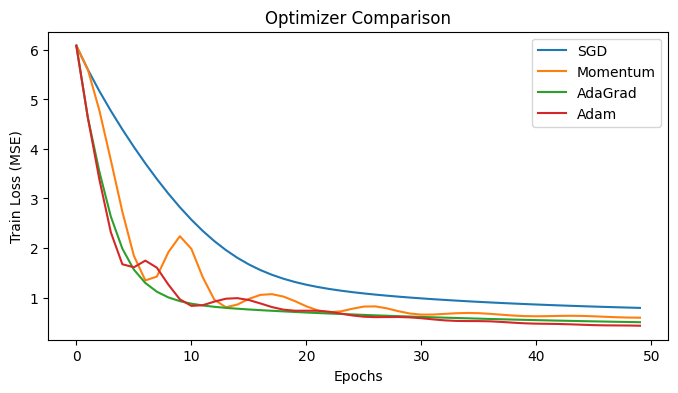

In [2]:
def create_mlp():
    return nn.Sequential(nn.Linear(8, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

optimizers = {
    'SGD': optim.SGD,
    'Momentum': lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    'AdaGrad': optim.Adagrad,
    'Adam': optim.Adam
}

plt.figure(figsize=(8, 4))

for name, opt_func in optimizers.items():
    torch.manual_seed(42)                  # 모든 옵티마이저가 같은 초기 가중치에서 시작
    model = create_mlp()
    opt = opt_func(model.parameters(), lr=0.01)
    losses = []

    for _ in range(50):
        opt.zero_grad()
        loss = criterion(model(X_train_t), y_train_t)
        loss.backward()
        opt.step()
        losses.append(loss.item())

    plt.plot(losses, label=name)
    print(f"{name:9s} 50 에폭 후 훈련 손실: {losses[-1]:.4f}")

plt.title('Optimizer Comparison')
plt.xlabel('Epochs')
plt.ylabel('Train Loss (MSE)')
plt.legend()
plt.show()

## **3. 2차원 손실 함수에서의 최적화 경로**

옆으로 길고 위아래로 가파른 계곡 모양의 함수 $f(x, y) = \frac{x^2}{20} + y^2$ 에서, 점 (-7, 2)를 출발해 최솟값 (0, 0)을 찾아가는 경로를 그립니다.  
학습률은 모두 0.8입니다.

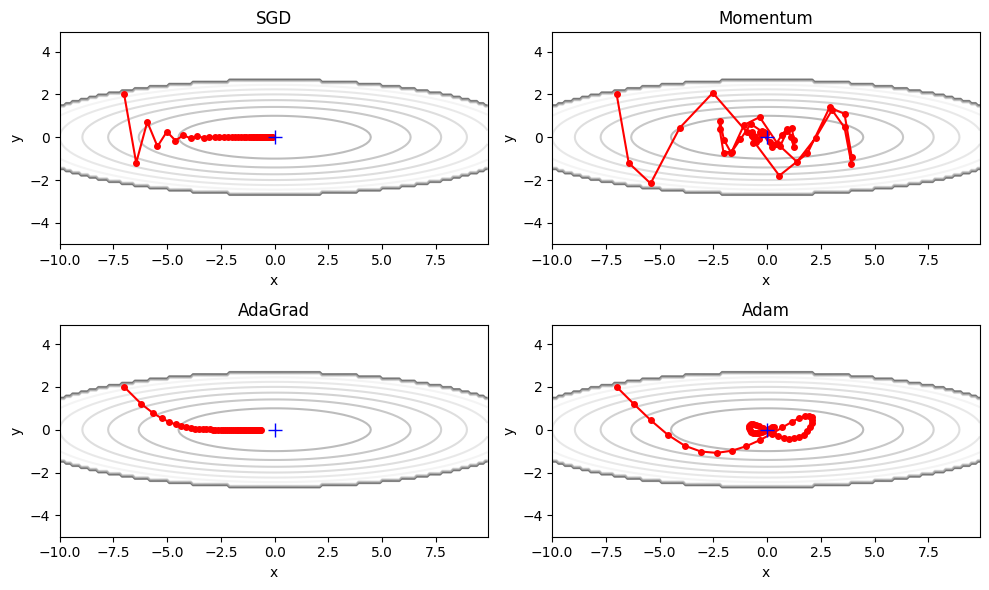

In [3]:
# 옆으로 길고 위아래로 가파른 계곡 모양의 손실 함수
def f(x, y): return x**2 / 20 + y**2

x_grid, y_grid = np.meshgrid(np.arange(-10, 10, 0.1), np.arange(-5, 5, 0.1))
Z = f(x_grid, y_grid)
Z[Z > 7] = 0

plt.figure(figsize=(10, 6))

for i, (name, opt_func) in enumerate(optimizers.items(), 1):
    p = torch.tensor([-7.0, 2.0], requires_grad=True)   # 출발점
    opt = opt_func([p], lr=0.8)
    path_x, path_y = [], []

    for _ in range(50):
        path_x.append(p[0].item())
        path_y.append(p[1].item())
        opt.zero_grad()
        loss = f(p[0], p[1])
        loss.backward()
        opt.step()                                       # 좌표 p 업데이트

    plt.subplot(2, 2, i)
    plt.contour(x_grid, y_grid, Z, cmap='gray', alpha=0.3)
    plt.plot(path_x, path_y, 'o-', color='red', markersize=4)
    plt.plot(0, 0, '+', color='blue', markersize=10)
    plt.title(name)
    plt.xlabel('x')
    plt.ylabel('y')

plt.tight_layout()
plt.show()

## **4. 과적합과 규제: L2 정규화와 드롭아웃**

과적합을 일부러 만들기 위해 **훈련 데이터를 500개만** 쓰고, 뉴런이 256개인 은닉층 3개의 넓은 모델을 1000 에폭 학습합니다.  
테스트는 전체 테스트 세트(4128개)로 합니다.

- **L2 정규화**: 옵티마이저의 `weight_decay`로 가중치 제곱합에 벌점을 줍니다.
- **드롭아웃**: 학습할 때 뉴런을 20% 확률로 끕니다. `model.eval()`이면 모든 뉴런을 사용합니다.

훈련 손실은 계속 내려가는데 테스트 손실이 다시 올라가면 과적합입니다.

Normal (Baseline)      최종 훈련 손실: 0.0023 | 최종 테스트 손실: 0.5714
L2 (weight_decay=0.03) 최종 훈련 손실: 0.2404 | 최종 테스트 손실: 0.4157
Dropout (p=0.2)        최종 훈련 손실: 0.0938 | 최종 테스트 손실: 0.4841


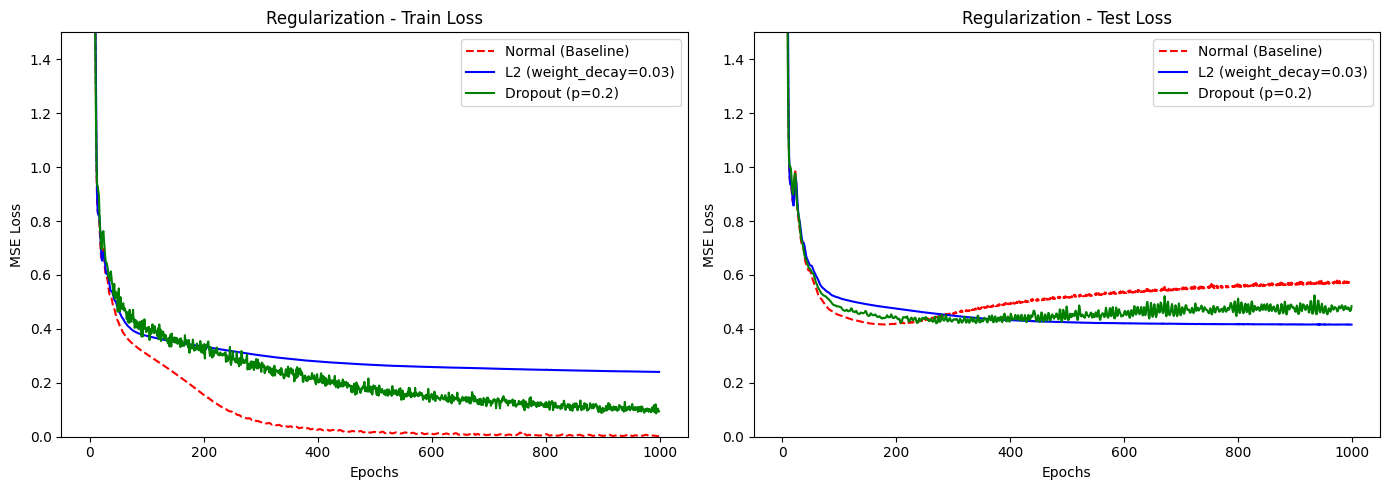

In [4]:
# 과적합 실험용: 훈련 데이터 500개
X_small, y_small = X_train_t[:500], y_train_t[:500]

class WideModel(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        layers = [nn.Linear(8, 256), nn.ReLU()]
        for _ in range(2):
            if dropout: layers.append(nn.Dropout(dropout))   # 드롭아웃
            layers += [nn.Linear(256, 256), nn.ReLU()]
        if dropout: layers.append(nn.Dropout(dropout))
        layers.append(nn.Linear(256, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_and_plot(models_dict, title, X_tr, y_tr, epochs, lr, y_max):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['red', 'blue', 'green', 'purple']

    for idx, (name, (make_model, weight_decay)) in enumerate(models_dict.items()):
        torch.manual_seed(42)                            # 모든 모델이 같은 조건에서 시작
        model = make_model()
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        train_losses, test_losses = [], []

        for epoch in range(epochs):
            model.train()                                # 학습 모드 (드롭아웃 켜짐)
            optimizer.zero_grad()
            loss = criterion(model(X_tr), y_tr)
            loss.backward()
            if epoch == 0 and hasattr(model, 'hidden_layers'):   # 첫 에폭의 층별 기울기 크기
                first = model.hidden_layers[0][0].weight.grad.norm().item()
                last = model.hidden_layers[-1][0].weight.grad.norm().item()
            optimizer.step()
            train_losses.append(loss.item())

            model.eval()                                 # 평가 모드 (드롭아웃 꺼짐)
            with torch.no_grad():
                test_losses.append(criterion(model(X_test_t), y_test_t).item())

        ls = '--' if 'Normal' in name else '-'
        axes[0].plot(train_losses, label=name, color=colors[idx], linestyle=ls)
        axes[1].plot(test_losses, label=name, color=colors[idx], linestyle=ls)
        msg = f"{name:22s} 최종 훈련 손실: {train_losses[-1]:.4f} | 최종 테스트 손실: {test_losses[-1]:.4f}"
        if hasattr(model, 'hidden_layers'):
            msg += f" | 기울기 크기(첫 은닉층 / 마지막 은닉층): {first:.1e} / {last:.1e}"
        print(msg)

    for ax, kind in zip(axes, ['Train', 'Test']):
        ax.set_title(f'{title} - {kind} Loss')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('MSE Loss')
        ax.set_ylim(0, y_max)
        ax.legend()

    plt.tight_layout()
    plt.show()

models_reg = {
    'Normal (Baseline)': (lambda: WideModel(), 0.0),
    'L2 (weight_decay=0.03)': (lambda: WideModel(), 0.03),
    'Dropout (p=0.2)': (lambda: WideModel(dropout=0.2), 0.0),
}
train_and_plot(models_reg, 'Regularization', X_small, y_small, epochs=1000, lr=0.001, y_max=1.5)

## **5. 기울기 소실: 정규화와 잔차 연결**

이번에는 반대로 **아주 깊은** 모델을 만듭니다. 뉴런 16개짜리 은닉층 **100개**에 활성화 함수는 시그모이드입니다.  
시그모이드의 미분값은 최대 0.25라서, 역전파 때 계속 곱해지면 입력 쪽 층의 기울기가 거의 0이 됩니다.  

배치 정규화, 층 정규화, 잔차 연결을 옵션으로 켜고 끌 수 있게 만들고, 훈련 데이터 전체로 100 에폭 학습합니다.  
결과에는 첫 에폭에서 **첫 은닉층과 마지막 은닉층의 기울기 크기**도 함께 출력합니다.

In [5]:
class DeepModel(nn.Module):
    def __init__(self, batchnorm=False, layernorm=False, residual=False):
        super().__init__()
        self.residual = residual
        hidden_dim = 16

        self.input_layer = nn.Sequential(nn.Linear(8, hidden_dim), nn.Sigmoid())   # 입력층

        self.hidden_layers = nn.ModuleList()
        for _ in range(100):                                                       # 은닉층 100개
            layers = [nn.Linear(hidden_dim, hidden_dim)]
            if batchnorm: layers.append(nn.BatchNorm1d(hidden_dim))                # 배치 정규화
            if layernorm: layers.append(nn.LayerNorm(hidden_dim))                  # 층 정규화
            layers.append(nn.Sigmoid())
            self.hidden_layers.append(nn.Sequential(*layers))

        self.output_layer = nn.Linear(hidden_dim, 1)                               # 출력층

    def forward(self, x):
        x = self.input_layer(x)
        for layer in self.hidden_layers:
            if self.residual:
                x = x + layer(x)      # 잔차 연결: 입력 x를 출력에 그대로 더함
            else:
                x = layer(x)
        return self.output_layer(x)

### **5-1. 배치 정규화와 층 정규화**

- **배치 정규화**: 배치 안에서 특성(뉴런)마다 평균 0, 분산 1로 맞춥니다.
- **층 정규화**: 샘플 하나 안에서 모든 특성을 평균 0, 분산 1로 맞춥니다.

Normal (Baseline)      최종 훈련 손실: 1.3368 | 최종 테스트 손실: 1.3108 | 기울기 크기(첫 은닉층 / 마지막 은닉층): 0.0e+00 / 1.2e+00
Batch Normalization    최종 훈련 손실: 0.5202 | 최종 테스트 손실: 0.6567 | 기울기 크기(첫 은닉층 / 마지막 은닉층): 1.7e+00 / 2.7e-01
Layer Normalization    최종 훈련 손실: 1.3369 | 최종 테스트 손실: 1.3105 | 기울기 크기(첫 은닉층 / 마지막 은닉층): 0.0e+00 / 3.0e+00


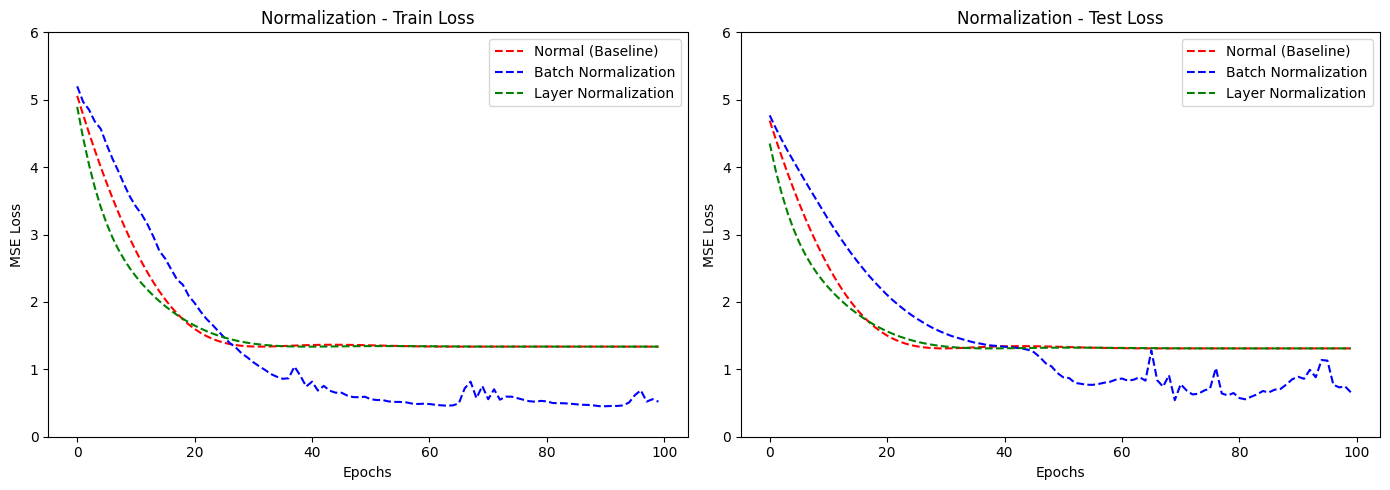

In [6]:
models_norm = {
    'Normal (Baseline)': (lambda: DeepModel(), 0.0),
    'Batch Normalization': (lambda: DeepModel(batchnorm=True), 0.0),
    'Layer Normalization': (lambda: DeepModel(layernorm=True), 0.0),
}
train_and_plot(models_norm, 'Normalization', X_train_t, y_train_t, epochs=100, lr=0.005, y_max=6.0)

### **5-2. 잔차 연결**

잔차 연결은 층의 출력에 입력을 그대로 더합니다($H(x) = x + F(x)$).  
미분하면 $1 + F'(x)$ 이므로, $F'(x)$가 0에 가까워도 기울기 1이 그대로 앞 층으로 전달됩니다.

Normal (Baseline)      최종 훈련 손실: 1.3368 | 최종 테스트 손실: 1.3108 | 기울기 크기(첫 은닉층 / 마지막 은닉층): 0.0e+00 / 1.2e+00
Residual Connection    최종 훈련 손실: 0.8933 | 최종 테스트 손실: 0.8750 | 기울기 크기(첫 은닉층 / 마지막 은닉층): 7.1e+00 / 6.7e-01


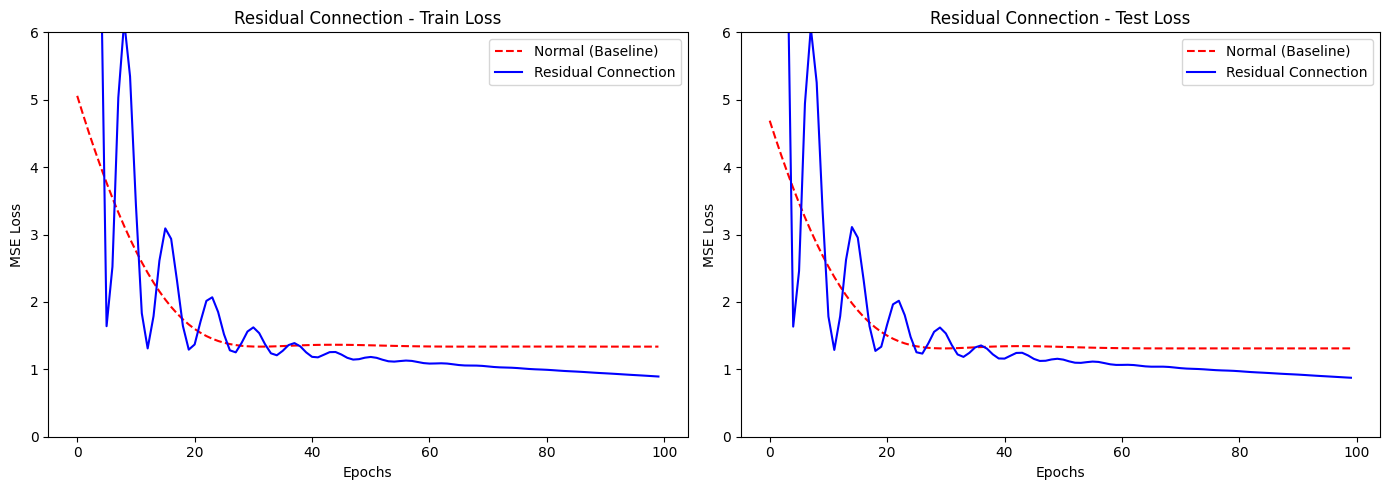

In [7]:
models_res = {
    'Normal (Baseline)': (lambda: DeepModel(), 0.0),
    'Residual Connection': (lambda: DeepModel(residual=True), 0.0),
}
train_and_plot(models_res, 'Residual Connection', X_train_t, y_train_t, epochs=100, lr=0.005, y_max=6.0)

## **6. 정리**

| 문제 | 해결 방법 | 이 노트북에서 확인한 것 |
|:---|:---|:---|
| 느리고 불안정한 수렴 | 모멘텀, AdaGrad, Adam | 옵티마이저에 따라 손실이 줄어드는 속도와 경로가 다름 |
| 과적합 | L2 정규화, 드롭아웃 | 테스트 손실이 다시 올라가는 것을 줄임 |
| 기울기 소실 | 배치 정규화, 잔차 연결 | 100층 모델에서도 입력 쪽 층까지 기울기가 전달되어 학습이 진행됨 |